Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 1s 292us/step - accuracy: 0.8291 - loss: 0.3885 - val_accuracy: 0.8428 - val_loss: 0.3488
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 252us/step - accuracy: 0.8480 - loss: 0.3510 - val_accuracy: 0.8490 - val_loss: 0.3362
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 255us/step - accuracy: 0.8498 - loss: 0.3458 - val_accuracy: 0.8522 - val_loss: 0.3409
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step - accuracy: 0.8524 - loss: 0.3407 - val_accuracy: 0.8520 - val_loss: 0.3322
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step - accuracy: 0.8547 - loss: 0.3370 - val_accuracy: 0.8533 - val_loss: 0.3296
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step - accuracy: 0.8559 - loss: 0.3343 - val_accuracy: 0.8533 - val_loss: 0.3382
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step - accuracy: 0.8566 - loss: 0.3320 - val_accuracy: 0.8570 - val_loss: 0.3324
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 0s 252us/step - accuracy: 0.8584 -

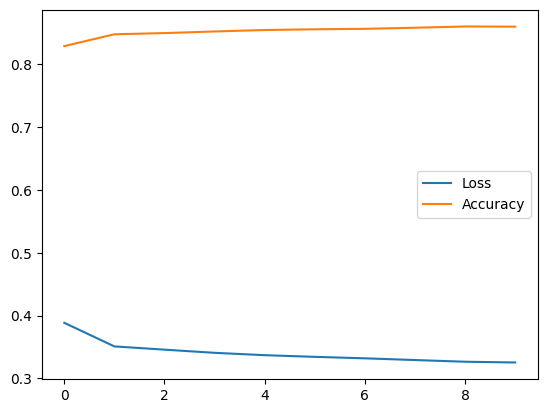

In [1]:
import pandas as pd
import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Data preparation
data = pd.read_csv("IMDB Dataset.csv")

def preprocess(text):
    text = re.sub(r"<.*?>", "", text.lower())
    words = re.findall(r"\b[a-z]+\b", text)
    return [w for w in words if w not in ENGLISH_STOP_WORDS]

X = data["review"].apply(preprocess)
y = data["sentiment"].map({"positive": 1, "negative": 0}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tokenize and pad sequences
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=200)
test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=200)

# 2. Train CBOW Word2Vec model
w2v = Word2Vec(
    sentences=X_train,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)

# 3. Convert documents into average word embeddings
def document_vector(sequence):
    vectors = [
        w2v.wv[tokenizer.index_word[i]]
        for i in sequence
        if i != 0 and tokenizer.index_word.get(i) in w2v.wv
    ]
    return np.mean(vectors, axis=0) if vectors else np.zeros(100)

x_train = np.array([document_vector(s) for s in train_seq])
x_test = np.array([document_vector(s) for s in test_seq])

# Define feedforward neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

# 4. Train and evaluate
history = model.fit(x_train, y_train, epochs=10,
                    validation_split=0.1)

print("Test results:", model.evaluate(x_test, y_test))

plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["accuracy"], label="Accuracy")
plt.legend()
plt.show()

In [2]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 13.5 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]2m1/2 [gensim]

[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
